# Predictive Maintenance: RUL Motor Induksi (XGBoost)

Notebook ini melatih model regresi untuk memprediksi **sisa umur pakai (RUL)** motor induksi, lalu membuat **grafik siap pakai untuk laporan**.

Setiap grafik tampil di notebook **dan** tersimpan otomatis sebagai PNG (resolusi 200 dpi) di folder `grafik/`. Di bagian akhir, semua grafik dan model dapat diunduh sebagai file ZIP.

**Cara memakai di Google Colab:** pilih **Runtime → Run all**, lalu unggah `dataset_motor_induksi_rul.csv` ketika diminta.

## 1. Setup lingkungan

In [1]:
import sys, subprocess, importlib, os, platform
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

def pastikan(paket, impor=None):
    # Install paket hanya jika belum ada (aman untuk Colab dan lokal)
    try:
        importlib.import_module(impor or paket)
    except ImportError:
        print("Menginstal", paket)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paket])

pastikan("xgboost"); pastikan("scikit-learn", "sklearn"); pastikan("pandas")
pastikan("matplotlib"); pastikan("joblib")

if IN_COLAB:
    ROOT = Path("/content/mkb-kasus3-rul")
else:
    ROOT = Path.cwd()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent

FIG_DIR = ROOT / "grafik"
for folder in (ROOT / "data", ROOT / "artifacts", FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
os.chdir(ROOT)
print("Colab:", IN_COLAB, "| ROOT:", ROOT, "| Grafik ->", FIG_DIR)

Colab: True | ROOT: /content/mkb-kasus3-rul | Grafik -> /content/mkb-kasus3-rul/grafik


## 2. Pengaturan grafik

Sel ini mengatur tampilan semua grafik (ukuran huruf, grid, warna status) dan membuat fungsi `simpan()` yang menampilkan sekaligus menyimpan grafik ke `grafik/`. Warna status sama dengan yang dipakai di aplikasi Streamlit.

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200,
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

WARNA = {"model": "#2563EB", "baseline": "#9CA3AF", "garis": "#DC2626", "netral": "#475569"}
URUTAN_STATUS = ["KRITIS", "PERHATIAN", "NORMAL", "PRIMA"]
WARNA_STATUS = {"KRITIS": "#DC2626", "PERHATIAN": "#F59E0B", "NORMAL": "#2563EB", "PRIMA": "#16A34A"}
BATAS_STATUS = [24, 100, 500]

def status_dari_rul(rul):
    return "PRIMA" if rul > 500 else "NORMAL" if rul > 100 else "PERHATIAN" if rul > 24 else "KRITIS"

def status_seri(nilai):
    return pd.cut(pd.Series(np.asarray(nilai, dtype=float)),
                  bins=[-np.inf, 24, 100, 500, np.inf], labels=URUTAN_STATUS)

def simpan(fig, nama, judul=None):
    # Tampilkan grafik, lalu simpan sebagai PNG di folder grafik/
    if judul:
        fig.suptitle(judul, fontsize=13, fontweight="bold")
        fig.tight_layout(rect=[0, 0, 1, 0.95])
    else:
        fig.tight_layout()
    path = FIG_DIR / f"{nama}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print("Tersimpan:", path.name)

## 3. Muat dataset

Atur `PAKAI_DATA_SINTETIS = True` hanya untuk menguji alur notebook tanpa dataset asli. Untuk laporan, pakai dataset asli.

In [25]:
PAKAI_DATA_SINTETIS = False

DATA_PATH = ROOT / "data" / "dataset_motor_induksi_rul dummy.csv"
FITUR_INPUT = ["arus_ampere", "getaran_mm_s", "suhu_body_c", "tegangan_volt"]
TARGET = "sisa_umur_jam"
NAMA_FITUR = {"arus_ampere": "Arus (A)", "getaran_mm_s": "Getaran (mm/s)",
              "suhu_body_c": "Suhu body (°C)", "tegangan_volt": "Tegangan (V)",
              "sisa_umur_jam": "Sisa umur (jam)"}

def buat_data_sintetis(n=1500, seed=42):
    rng = np.random.default_rng(seed)
    kerusakan = rng.uniform(0, 1, n)
    d = pd.DataFrame({
        "arus_ampere":   10 + 12 * kerusakan + rng.normal(0, 0.8, n),
        "getaran_mm_s":  1 + 10 * kerusakan**1.5 + rng.normal(0, 0.4, n),
        "suhu_body_c":   40 + 45 * kerusakan + rng.normal(0, 3, n),
        "tegangan_volt": 220 + rng.normal(0, 2, n),
    })
    d[TARGET] = (2500 * (1 - kerusakan) ** 1.3 + rng.normal(0, 40, n)).clip(1).round(2)
    d.loc[rng.choice(n, 40, replace=False), "suhu_body_c"] = np.nan
    d.loc[rng.choice(n, 15, replace=False), "getaran_mm_s"] = -1
    return pd.concat([d, d.sample(20, random_state=1)], ignore_index=True)

if PAKAI_DATA_SINTETIS:
    df = buat_data_sintetis()
    print("Memakai DATA SINTETIS (hanya untuk uji alur).")
else:
    if not DATA_PATH.exists() and IN_COLAB:
        from google.colab import files
        print("Unggah dataset_motor_induksi_rul.csv")
        up = files.upload()
        DATA_PATH.write_bytes(up[next(iter(up))])
    assert DATA_PATH.exists(), f"Dataset tidak ditemukan di {DATA_PATH}"
    df = pd.read_csv(DATA_PATH)

kurang = [c for c in FITUR_INPUT + [TARGET] if c not in df.columns]
assert not kurang, f"Kolom hilang: {kurang}"

print("Ukuran data:", df.shape)
if len(df) < 50:
    print(f"PERINGATAN: hanya {len(df)} baris. Metrik dan grafik tidak bermakna; pakai dataset penuh.")
df.head()

Unggah dataset_motor_induksi_rul.csv


Saving dataset_motor_induksi_rul_dummy.csv to dataset_motor_induksi_rul_dummy.csv
Ukuran data: (1000, 6)


,index,arus_ampere,getaran_mm_s,suhu_body_c,tegangan_volt,sisa_umur_jam
0,0,16.754344,7.159649,74.008931,217.808535,203.47
1,1,18.351245,8.773094,84.369209,220.690337,41.07
2,2,11.822560,1.257678,45.590503,218.474861,2093.90
3,3,13.501390,2.865585,57.255625,219.115170,1119.77
4,4,17.377693,8.066450,76.699494,223.242913,91.95


## 4. Eksplorasi data (EDA)

Bagian ini menghasilkan **Grafik 01 sampai 04**: kualitas data, sebaran, hubungan sensor dengan RUL, dan korelasi. Untuk laporan, grafik ini cocok di bab deskripsi data.

In [26]:
kolom = FITUR_INPUT + [TARGET]
kualitas = pd.DataFrame({"nilai_kosong": df[kolom].isna().sum(),
                         "nilai_negatif": (df[kolom] < 0).sum()})
print(f"Ukuran: {df.shape} | Baris duplikat: {df.duplicated().sum()}")
display(kualitas)
display(df[kolom].describe().T.round(3))

Ukuran: (1000, 6) | Baris duplikat: 0


,nilai_kosong,nilai_negatif
arus_ampere,12,5
getaran_mm_s,12,10
suhu_body_c,40,0
tegangan_volt,0,0
sisa_umur_jam,0,0


,count,mean,std,min,25%,50%,75%,max
arus_ampere,988.0,13.975,2.232,-1.000,12.412,13.965,15.666,18.381
getaran_mm_s,988.0,4.225,2.329,-1.000,2.292,3.865,6.170,9.438
suhu_body_c,960.0,59.713,10.419,35.587,51.525,59.124,68.405,84.369
tegangan_volt,1000.0,219.924,1.477,215.475,218.919,219.907,220.903,226.039
sisa_umur_jam,1000.0,1038.796,680.408,1.000,432.575,1017.820,1605.812,2785.810


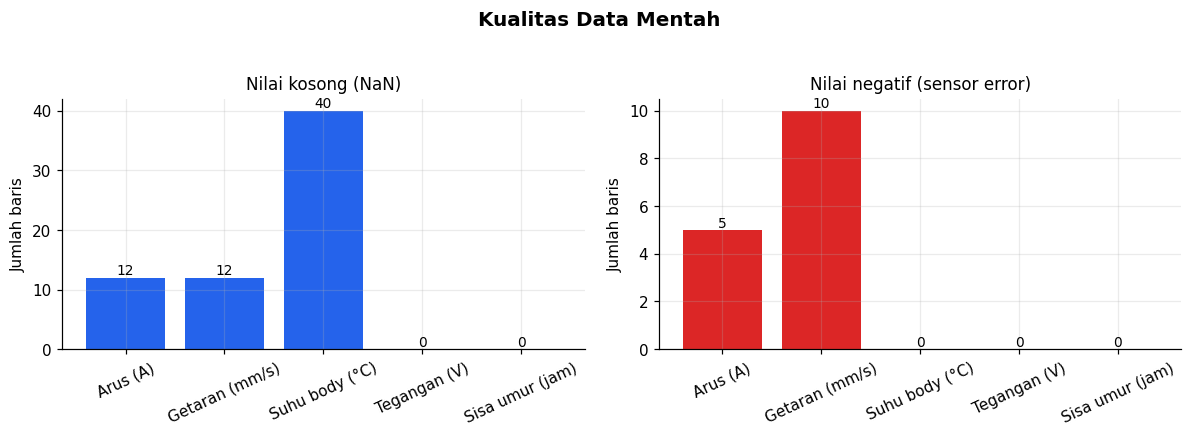

Tersimpan: 01_kualitas_data.png


In [27]:
# Grafik 01: kualitas data (nilai kosong dan negatif per kolom)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, kolom_k, warna, judul in [(ax[0], "nilai_kosong", WARNA["model"], "Nilai kosong (NaN)"),
                                 (ax[1], "nilai_negatif", WARNA["garis"], "Nilai negatif (sensor error)")]:
    nilai = kualitas[kolom_k]
    batang = a.bar([NAMA_FITUR[k] for k in nilai.index], nilai.values, color=warna)
    a.set_title(judul); a.set_ylabel("Jumlah baris")
    a.tick_params(axis="x", rotation=25)
    for b, v in zip(batang, nilai.values):
        a.text(b.get_x() + b.get_width() / 2, v, str(int(v)), ha="center", va="bottom", fontsize=9)
simpan(fig, "01_kualitas_data", "Kualitas Data Mentah")

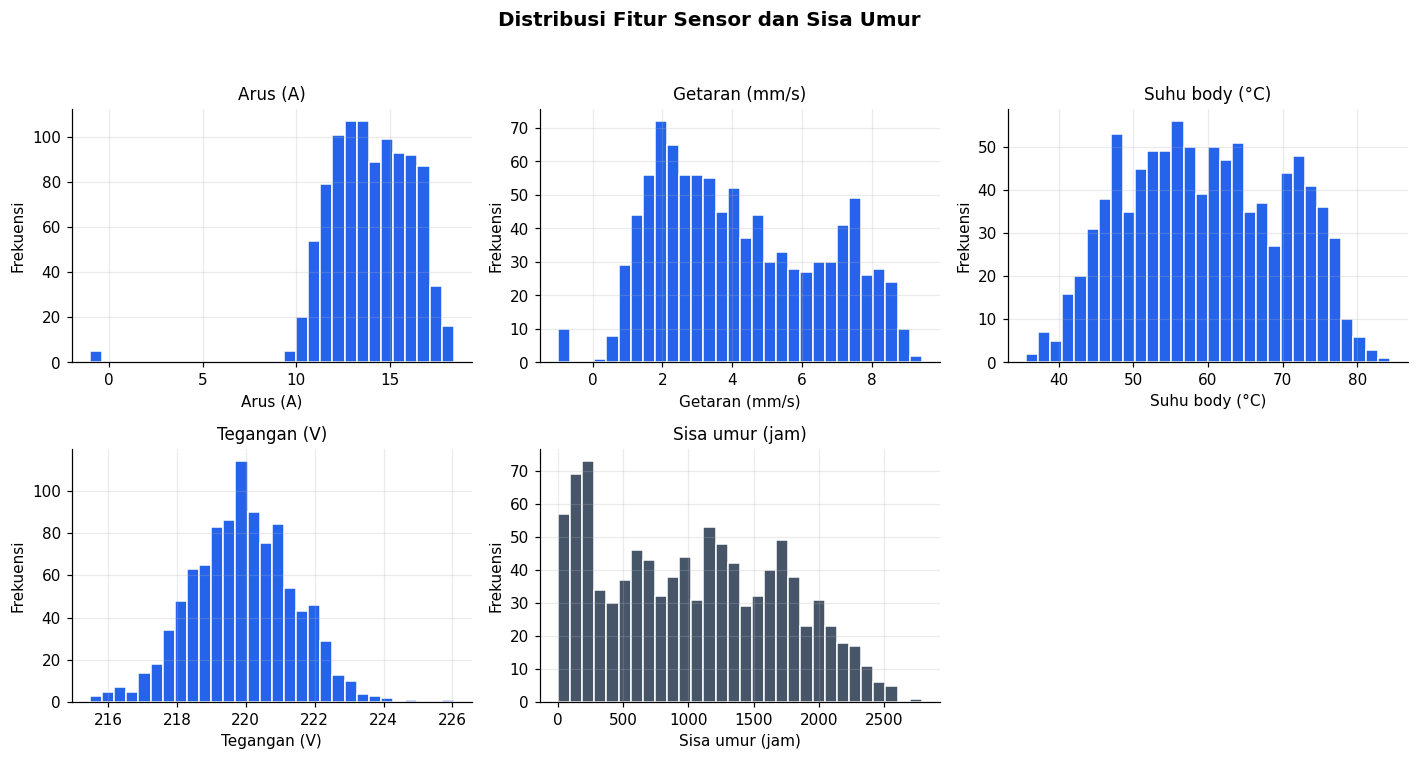

Tersimpan: 02_distribusi_data.png


In [28]:
# Grafik 02: distribusi setiap fitur dan target
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for a, k in zip(axes.ravel(), kolom):
    a.hist(df[k].dropna(), bins=30, color=WARNA["model"] if k != TARGET else WARNA["netral"], edgecolor="white")
    a.set_title(NAMA_FITUR[k]); a.set_xlabel(NAMA_FITUR[k]); a.set_ylabel("Frekuensi")
axes.ravel()[-1].axis("off")
simpan(fig, "02_distribusi_data", "Distribusi Fitur Sensor dan Sisa Umur")

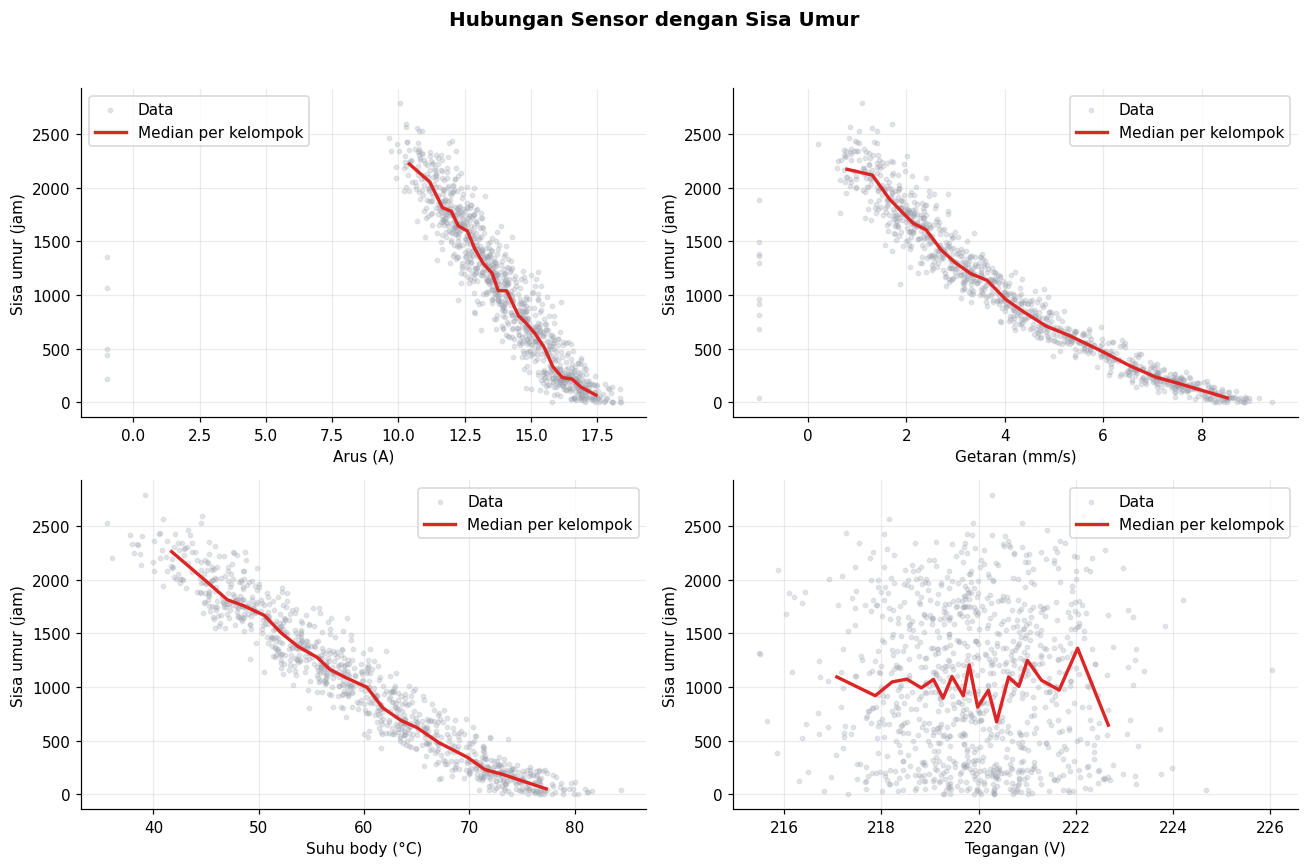

Tersimpan: 03_hubungan_sensor_vs_rul.png


In [29]:
# Grafik 03: hubungan tiap sensor dengan sisa umur (titik data + median per kelompok)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for a, k in zip(axes.ravel(), FITUR_INPUT):
    d = df[[k, TARGET]].dropna()
    a.scatter(d[k], d[TARGET], s=8, alpha=0.25, color=WARNA["baseline"], label="Data")
    kel = pd.qcut(d[k], q=20, duplicates="drop")
    tren = d.groupby(kel, observed=True).median()
    a.plot(tren[k], tren[TARGET], color=WARNA["garis"], lw=2.2, label="Median per kelompok")
    a.set_xlabel(NAMA_FITUR[k]); a.set_ylabel("Sisa umur (jam)"); a.legend()
simpan(fig, "03_hubungan_sensor_vs_rul", "Hubungan Sensor dengan Sisa Umur")

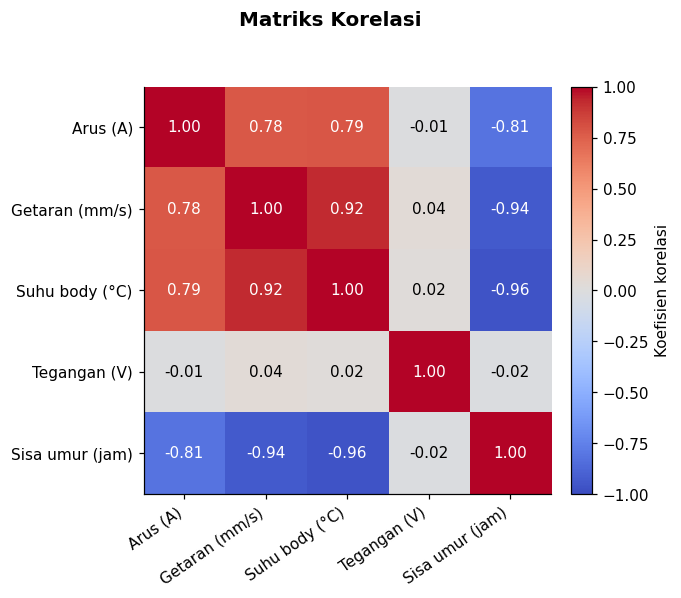

Tersimpan: 04_korelasi.png


In [30]:
# Grafik 04: matriks korelasi (Pearson)
korelasi = df[kolom].corr()
fig, a = plt.subplots(figsize=(6.5, 5.5))
im = a.imshow(korelasi.values, cmap="coolwarm", vmin=-1, vmax=1)
nama = [NAMA_FITUR[k] for k in korelasi.columns]
a.set_xticks(range(len(nama))); a.set_xticklabels(nama, rotation=35, ha="right")
a.set_yticks(range(len(nama))); a.set_yticklabels(nama)
a.grid(False)
for i in range(len(nama)):
    for j in range(len(nama)):
        v = korelasi.values[i, j]
        a.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.55 else "black")
fig.colorbar(im, ax=a, fraction=0.046, pad=0.04, label="Koefisien korelasi")
simpan(fig, "04_korelasi", "Matriks Korelasi")

## 5. Pembersihan dan pipeline

Baris duplikat dan baris tanpa target valid dibuang. Nilai negatif pada arus dan getaran dianggap sensor error, diubah menjadi `NaN`, lalu diisi median data latih di dalam pipeline.

In [31]:
n_awal = len(df)
n_duplikat = int(df.duplicated().sum())
df = df.drop_duplicates()
n_target_kosong = int(df[TARGET].isna().sum())
df = df.dropna(subset=[TARGET])
n_target_negatif = int((df[TARGET] < 0).sum())
df = df[df[TARGET] >= 0].reset_index(drop=True)
print(f"Awal: {n_awal} baris | duplikat dibuang: {n_duplikat} | target kosong: {n_target_kosong} | "
      f"target negatif: {n_target_negatif} | sisa: {len(df)} baris")

Awal: 1000 baris | duplikat dibuang: 0 | target kosong: 0 | target negatif: 0 | sisa: 1000 baris


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor

def bersihkan_data(df_in):
    # Nilai negatif pada arus/getaran dianggap sensor error -> NaN (diimputasi median)
    df_bersih = df_in.copy()
    df_bersih.loc[df_bersih["getaran_mm_s"] < 0, "getaran_mm_s"] = np.nan
    df_bersih.loc[df_bersih["arus_ampere"] < 0, "arus_ampere"] = np.nan
    return df_bersih

def buat_pipeline():
    return Pipeline([
        ("cleaning", FunctionTransformer(bersihkan_data)),
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)),
    ])

## 6. Latih dan evaluasi

Model dibandingkan dengan **baseline** yang selalu menebak rata-rata RUL data latih. Model dianggap berguna hanya jika galatnya lebih kecil daripada baseline. Validasi silang 5-lipat (hanya pada data latih) memberi gambaran apakah hasilnya stabil.

In [33]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X, y = df[FITUR_INPUT], df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

pipe = buat_pipeline().fit(X_tr, y_tr)
base = Pipeline([("imputer", SimpleImputer(strategy="median")),
                 ("m", DummyRegressor(strategy="mean"))]).fit(X_tr, y_tr)

pred = pipe.predict(X_te).clip(min=0)
pred_base = base.predict(X_te)

# Menentukan jumlah fold secara dinamis agar tidak error jika jumlah data terlalu sedikit
n_splits = min(5, len(X_tr))
cv = -cross_val_score(buat_pipeline(), X_tr, y_tr, cv=n_splits, scoring="neg_mean_absolute_error") if n_splits > 1 else np.array([0.0])

metrik = {
    "mae_model":     float(mean_absolute_error(y_te, pred)),
    "rmse_model":    float(np.sqrt(mean_squared_error(y_te, pred))),
    "r2_model":      float(r2_score(y_te, pred)) if len(y_te) > 1 else 0.0,
    "mae_baseline":  float(mean_absolute_error(y_te, pred_base)),
    "rmse_baseline": float(np.sqrt(mean_squared_error(y_te, pred_base))),
    "r2_baseline":   float(r2_score(y_te, pred_base)) if len(y_te) > 1 else 0.0,
    "cv_mae_mean":   float(cv.mean()),
    "cv_mae_std":    float(cv.std()),
    "akurasi_status_model": float((status_seri(y_te).values == status_seri(pred).values).mean()),
    "n_train": int(len(X_tr)), "n_test": int(len(X_te)),
}
metrik["mae_turun_persen"] = round(100 * (1 - metrik["mae_model"] / metrik["mae_baseline"]), 1) if metrik["mae_baseline"] > 0 else 0.0

tabel = pd.DataFrame({
    "Baseline (rata-rata)": [metrik["mae_baseline"], metrik["rmse_baseline"], metrik["r2_baseline"]],
    "XGBoost":              [metrik["mae_model"], metrik["rmse_model"], metrik["r2_model"]],
}, index=["MAE (jam)", "RMSE (jam)", "R2"]).round(3)
display(tabel)
print(f"MAE turun {metrik['mae_turun_persen']}% dibanding baseline | "
      f"CV MAE ({n_splits}-lipat): {metrik['cv_mae_mean']:.2f} +/- {metrik['cv_mae_std']:.2f} jam | "
      f"Akurasi status: {100*metrik['akurasi_status_model']:.1f}%")
if metrik["mae_model"] >= metrik["mae_baseline"]:
    print("PERINGATAN: model TIDAK mengalahkan baseline. Periksa data dan pipeline sebelum lanjut.")

,Baseline (rata-rata),XGBoost
MAE (jam),575.975,92.432
RMSE (jam),680.229,133.007
R2,-0.006,0.962


MAE turun 84.0% dibanding baseline | CV MAE (5-lipat): 95.41 +/- 2.54 jam | Akurasi status: 94.0%


## 7. Grafik hasil evaluasi

Bagian ini menghasilkan **Grafik 05 sampai 11** untuk bab hasil dan pembahasan laporan.

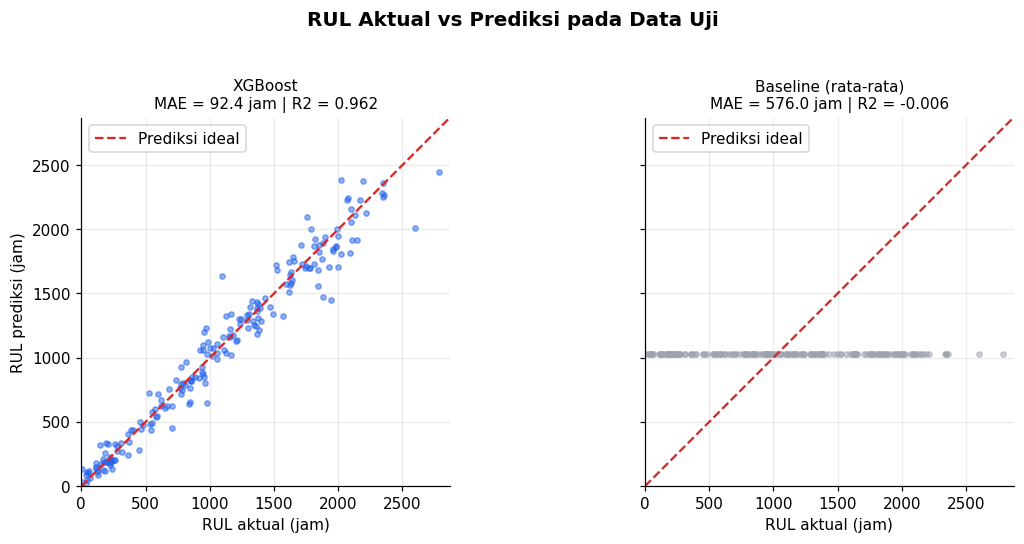

Tersimpan: 05_aktual_vs_prediksi.png


In [34]:
# Grafik 05: RUL aktual vs prediksi (model vs baseline)
batas = max(float(y_te.max()), float(pred.max()), float(pred_base.max())) * 1.03
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for a, p, warna, judul, ket in [
    (ax[0], pred, WARNA["model"], "XGBoost", f"MAE = {metrik['mae_model']:.1f} jam | R2 = {metrik['r2_model']:.3f}"),
    (ax[1], pred_base, WARNA["baseline"], "Baseline (rata-rata)", f"MAE = {metrik['mae_baseline']:.1f} jam | R2 = {metrik['r2_baseline']:.3f}")]:
    a.scatter(y_te, p, s=12, alpha=0.5, color=warna)
    a.plot([0, batas], [0, batas], "--", color=WARNA["garis"], lw=1.5, label="Prediksi ideal")
    a.set_xlim(0, batas); a.set_ylim(0, batas); a.set_aspect("equal")
    a.set_title(f"{judul}\n{ket}", fontsize=10)
    a.set_xlabel("RUL aktual (jam)"); a.legend(loc="upper left")
ax[0].set_ylabel("RUL prediksi (jam)")
simpan(fig, "05_aktual_vs_prediksi", "RUL Aktual vs Prediksi pada Data Uji")

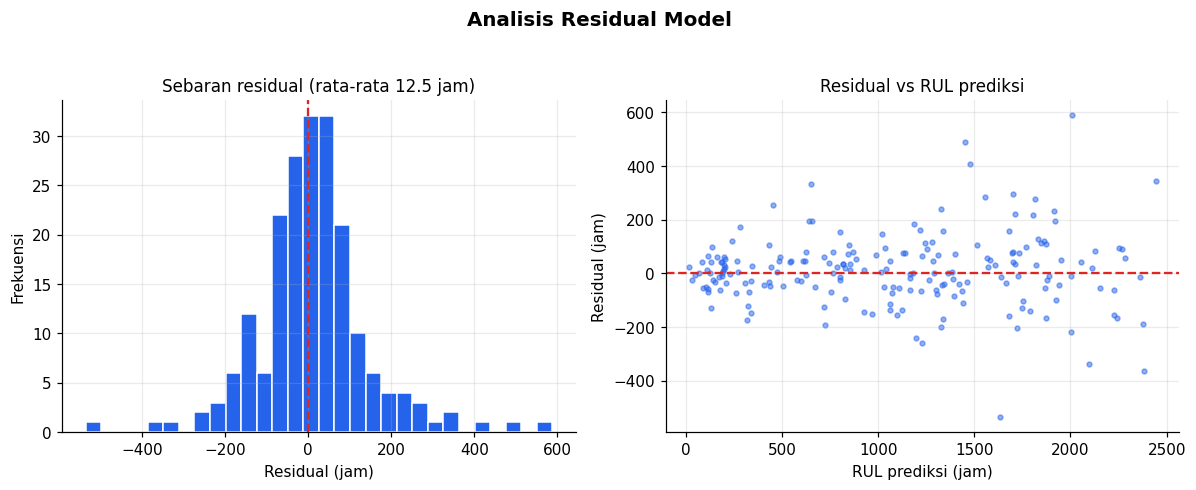

Tersimpan: 06_residual.png


In [35]:
# Grafik 06: analisis residual (aktual - prediksi)
residu = y_te.values - pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].hist(residu, bins=30, color=WARNA["model"], edgecolor="white")
ax[0].axvline(0, color=WARNA["garis"], ls="--")
ax[0].set_title(f"Sebaran residual (rata-rata {residu.mean():.1f} jam)")
ax[0].set_xlabel("Residual (jam)"); ax[0].set_ylabel("Frekuensi")
ax[1].scatter(pred, residu, s=10, alpha=0.5, color=WARNA["model"])
ax[1].axhline(0, color=WARNA["garis"], ls="--")
ax[1].set_title("Residual vs RUL prediksi")
ax[1].set_xlabel("RUL prediksi (jam)"); ax[1].set_ylabel("Residual (jam)")
simpan(fig, "06_residual", "Analisis Residual Model")

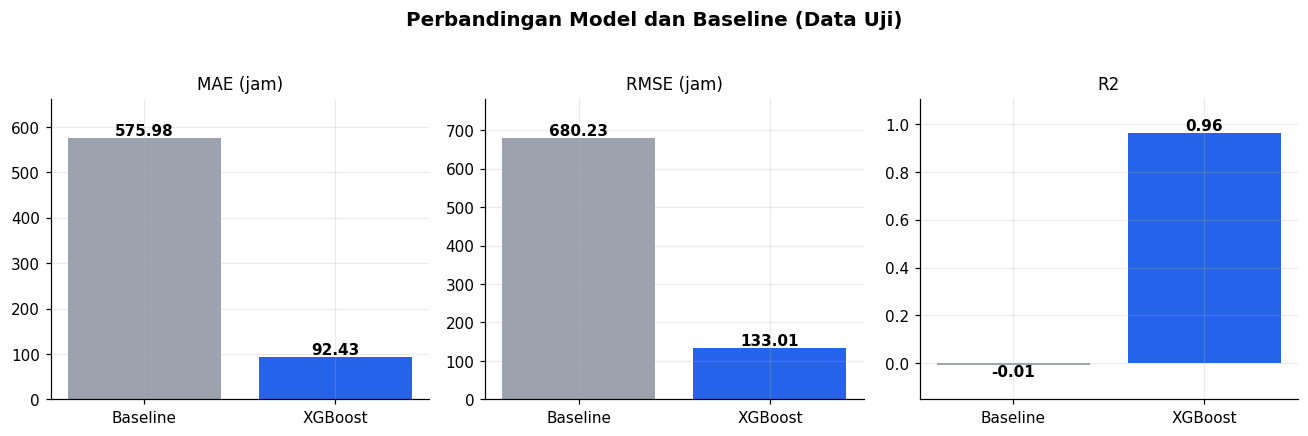

Tersimpan: 07_perbandingan_metrik.png


In [36]:
# Grafik 07: perbandingan metrik model vs baseline
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (nama, kunci) in zip(ax, [("MAE (jam)", "mae"), ("RMSE (jam)", "rmse"), ("R2", "r2")]):
    nilai = [metrik[f"{kunci}_baseline"], metrik[f"{kunci}_model"]]
    batang = a.bar(["Baseline", "XGBoost"], nilai, color=[WARNA["baseline"], WARNA["model"]])
    a.set_title(nama)
    for b, v in zip(batang, nilai):
        a.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center",
               va="bottom" if v >= 0 else "top", fontsize=10, fontweight="bold")
    a.margins(y=0.15)
simpan(fig, "07_perbandingan_metrik", "Perbandingan Model dan Baseline (Data Uji)")

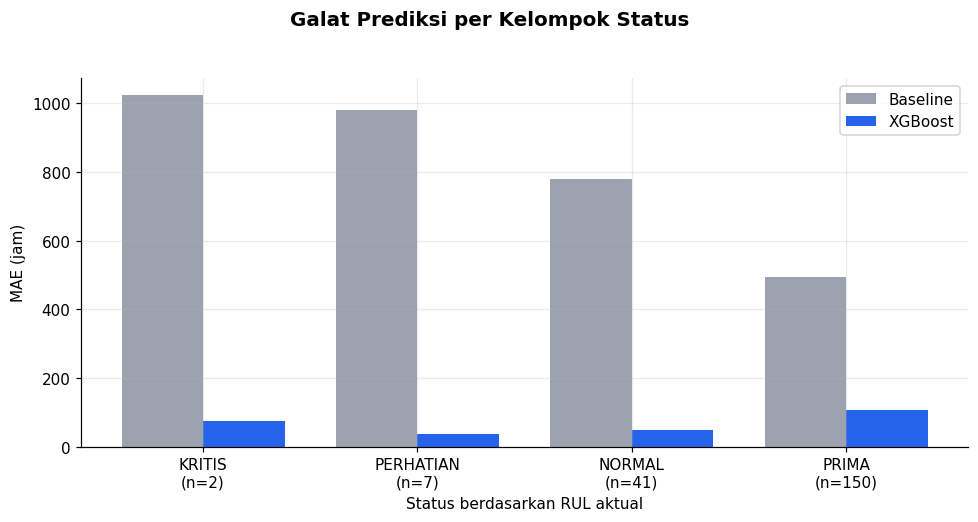

Tersimpan: 08_galat_per_status.png


,model,baseline,n
kel,,,
KRITIS,75.79,1023.22,2
PERHATIAN,37.25,979.96,7
NORMAL,48.96,779.39,41
PRIMA,107.11,495.56,150


In [37]:
# Grafik 08: galat (MAE) per kelompok status RUL aktual
kel = status_seri(y_te).values
hasil = pd.DataFrame({"kel": kel, "model": np.abs(y_te.values - pred), "baseline": np.abs(y_te.values - pred_base)})
per_status = hasil.groupby("kel", observed=False).agg(model=("model", "mean"), baseline=("baseline", "mean"),
                                                      n=("model", "size")).reindex(URUTAN_STATUS)
x = np.arange(len(URUTAN_STATUS)); lebar = 0.38
fig, a = plt.subplots(figsize=(9, 4.8))
a.bar(x - lebar / 2, per_status["baseline"], lebar, color=WARNA["baseline"], label="Baseline")
a.bar(x + lebar / 2, per_status["model"], lebar, color=WARNA["model"], label="XGBoost")
a.set_xticks(x)
a.set_xticklabels([f"{s}\n(n={int(per_status.loc[s, 'n'])})" for s in URUTAN_STATUS])
a.set_ylabel("MAE (jam)"); a.set_xlabel("Status berdasarkan RUL aktual"); a.legend()
simpan(fig, "08_galat_per_status", "Galat Prediksi per Kelompok Status")
display(per_status.round(2))

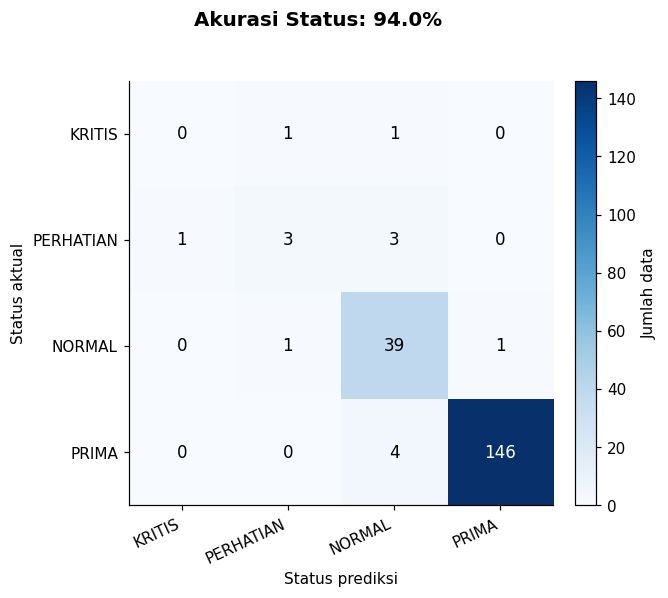

Tersimpan: 09_matriks_konfusi_status.png


In [38]:
# Grafik 09: matriks konfusi status (aktual vs prediksi)
aktual_s = pd.Categorical(status_seri(y_te).values, categories=URUTAN_STATUS)
prediksi_s = pd.Categorical(status_seri(pred).values, categories=URUTAN_STATUS)
konfusi = pd.crosstab(aktual_s, prediksi_s, dropna=False).reindex(index=URUTAN_STATUS, columns=URUTAN_STATUS, fill_value=0)
fig, a = plt.subplots(figsize=(6.5, 5.5))
im = a.imshow(konfusi.values, cmap="Blues")
a.set_xticks(range(4)); a.set_xticklabels(URUTAN_STATUS, rotation=25, ha="right")
a.set_yticks(range(4)); a.set_yticklabels(URUTAN_STATUS)
a.set_xlabel("Status prediksi"); a.set_ylabel("Status aktual"); a.grid(False)
puncak = konfusi.values.max() if konfusi.values.max() > 0 else 1
for i in range(4):
    for j in range(4):
        v = int(konfusi.values[i, j])
        a.text(j, i, str(v), ha="center", va="center", color="white" if v > puncak / 2 else "black", fontsize=11)
fig.colorbar(im, ax=a, fraction=0.046, pad=0.04, label="Jumlah data")
simpan(fig, "09_matriks_konfusi_status", f"Akurasi Status: {100*metrik['akurasi_status_model']:.1f}%")

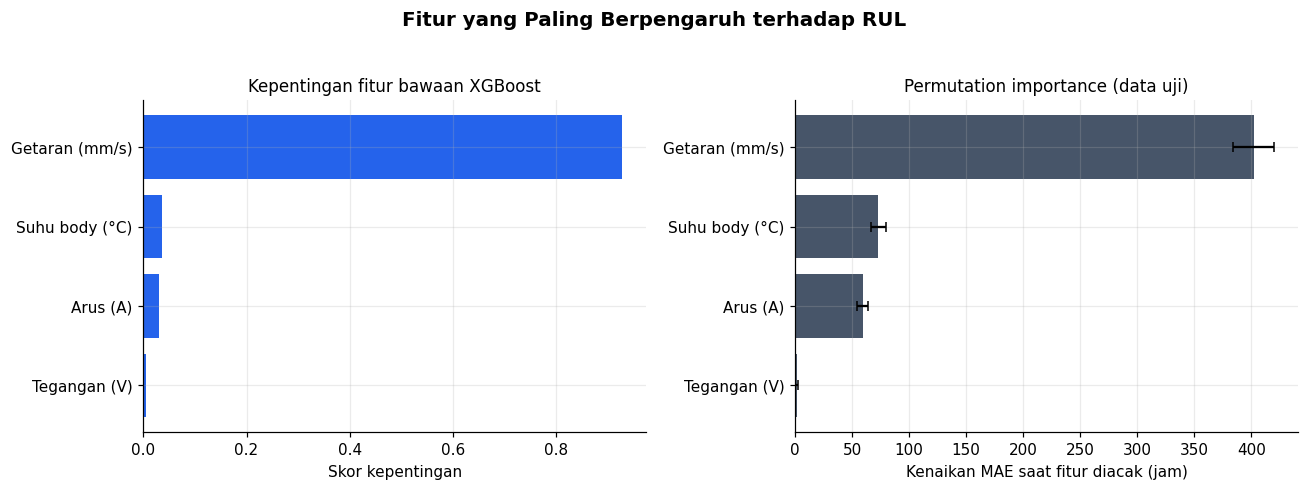

Tersimpan: 10_kepentingan_fitur.png


In [39]:
# Grafik 10: kepentingan fitur (bawaan XGBoost dan permutation importance)
from sklearn.inspection import permutation_importance

imp_xgb = pd.Series(pipe.named_steps["model"].feature_importances_, index=FITUR_INPUT)
perm = permutation_importance(pipe, X_te, y_te, scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=42)
imp_perm = pd.Series(perm.importances_mean, index=FITUR_INPUT)
std_perm = pd.Series(perm.importances_std, index=FITUR_INPUT)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
urut = imp_xgb.sort_values()
ax[0].barh([NAMA_FITUR[k] for k in urut.index], urut.values, color=WARNA["model"])
ax[0].set_title("Kepentingan fitur bawaan XGBoost"); ax[0].set_xlabel("Skor kepentingan")
urut2 = imp_perm.sort_values()
ax[1].barh([NAMA_FITUR[k] for k in urut2.index], urut2.values, xerr=std_perm[urut2.index].values,
           color=WARNA["netral"], capsize=3)
ax[1].set_title("Permutation importance (data uji)"); ax[1].set_xlabel("Kenaikan MAE saat fitur diacak (jam)")
simpan(fig, "10_kepentingan_fitur", "Fitur yang Paling Berpengaruh terhadap RUL")

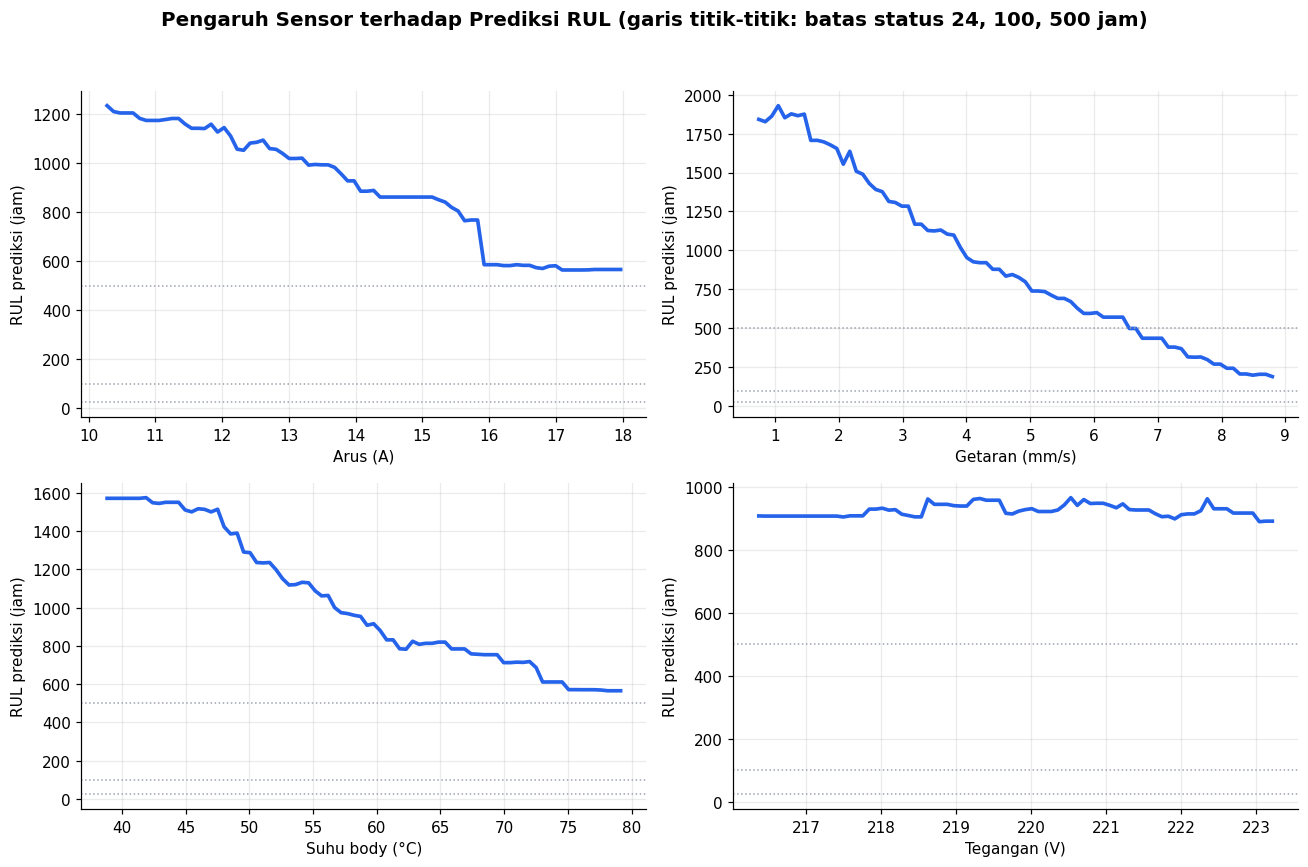

Tersimpan: 11_pengaruh_sensor_terhadap_rul.png


In [40]:
# Grafik 11: pengaruh tiap sensor terhadap prediksi RUL (fitur lain dibuat tetap di median)
X_bersih = bersihkan_data(X_tr)  # buang nilai sensor error (negatif) dari rentang grafik
dasar = X_bersih.median()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for a, k in zip(axes.ravel(), FITUR_INPUT):
    grid = np.linspace(X_bersih[k].quantile(0.01), X_bersih[k].quantile(0.99), 80)
    uji = pd.DataFrame([dasar.values] * len(grid), columns=FITUR_INPUT)
    uji[k] = grid
    a.plot(grid, pipe.predict(uji).clip(min=0), color=WARNA["model"], lw=2.4)
    for b in BATAS_STATUS:
        a.axhline(b, color=WARNA["baseline"], ls=":", lw=1)
    a.set_xlabel(NAMA_FITUR[k]); a.set_ylabel("RUL prediksi (jam)")
simpan(fig, "11_pengaruh_sensor_terhadap_rul", "Pengaruh Sensor terhadap Prediksi RUL (garis titik-titik: batas status 24, 100, 500 jam)")

## 8. Ringkasan untuk laporan

Tabel di bawah siap ditempel ke bab 4 laporan, dan semua angka juga tersimpan di `grafik/ringkasan_metrik.csv`.

In [41]:
tabel.to_csv(FIG_DIR / "ringkasan_metrik.csv")

baris = ["| Metrik (data uji) | Baseline (rata-rata) | XGBoost |", "|---|---|---|"]
for nama_baris, r in tabel.iterrows():
    baris.append(f"| {nama_baris} | {r['Baseline (rata-rata)']} | {r['XGBoost']} |")
print("\n".join(baris))
print()
print(f"Data latih: {metrik['n_train']} | Data uji: {metrik['n_test']}")
print(f"MAE model turun {metrik['mae_turun_persen']}% dibanding baseline.")
print(f"CV MAE 5-lipat: {metrik['cv_mae_mean']:.2f} +/- {metrik['cv_mae_std']:.2f} jam")
print(f"Akurasi klasifikasi status: {100*metrik['akurasi_status_model']:.1f}%")
print(f"Fitur terpenting (permutation): {imp_perm.idxmax()}")

| Metrik (data uji) | Baseline (rata-rata) | XGBoost |
|---|---|---|
| MAE (jam) | 575.975 | 92.432 |
| RMSE (jam) | 680.229 | 133.007 |
| R2 | -0.006 | 0.962 |

Data latih: 800 | Data uji: 200
MAE model turun 84.0% dibanding baseline.
CV MAE 5-lipat: 95.41 +/- 2.54 jam
Akurasi klasifikasi status: 94.0%
Fitur terpenting (permutation): getaran_mm_s


## 9. Simpan model portabel dan metadata

Model disimpan sebagai booster XGBoost (JSON) dan imputer (joblib), bukan satu pipeline utuh, agar dapat dimuat di aplikasi tanpa fungsi pembersihan buatan sendiri. Atur `SIMPAN_KE_ARTIFACTS = False` bila tidak ingin menimpa folder `artifacts/`.

In [42]:
import json, joblib, sklearn, xgboost

SIMPAN_KE_ARTIFACTS = True
OUT_DIR = ROOT / "artifacts" if SIMPAN_KE_ARTIFACTS else ROOT / "artifacts" / "retrained"
OUT_DIR.mkdir(parents=True, exist_ok=True)

pipe.named_steps["model"].get_booster().save_model(str(OUT_DIR / "xgb_rul.json"))
joblib.dump(pipe.named_steps["imputer"], OUT_DIR / "imputer_rul.joblib")

meta = {
    "versi_model": "1.0.0",
    "algoritma": "XGBRegressor (n_estimators=300, lr=0.05, max_depth=5) dalam Pipeline cleaning->imputer(median)->model",
    "format_model": "booster XGBoost (JSON) + imputer (joblib)",
    "fitur_input": FITUR_INPUT,
    "target": TARGET,
    "metrik_test": metrik,
    "data_sintetis": PAKAI_DATA_SINTETIS,
    "library": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(OUT_DIR / "metadata.json").write_text(json.dumps(meta, indent=2))
for f in ("xgb_rul.json", "imputer_rul.joblib", "metadata.json"):
    print("Tersimpan:", OUT_DIR / f, f"({(OUT_DIR / f).stat().st_size/1024:.0f} KB)")

Tersimpan: /content/mkb-kasus3-rul/artifacts/xgb_rul.json (765 KB)
Tersimpan: /content/mkb-kasus3-rul/artifacts/imputer_rul.joblib (1 KB)
Tersimpan: /content/mkb-kasus3-rul/artifacts/metadata.json (1 KB)


## 10. Uji prediksi dari model yang tersimpan

Model dimuat ulang dari disk dan dibandingkan dengan model di memori, lalu dicoba pada tiga kasus. Status: `PRIMA` lebih dari 500 jam, `NORMAL` lebih dari 100, `PERHATIAN` lebih dari 24, `KRITIS` 24 jam atau kurang.

In [45]:
import xgboost as xgb

def muat_portabel(folder):
    booster = xgb.Booster()
    booster.load_model(str(folder / "xgb_rul.json"))
    imputer = joblib.load(folder / "imputer_rul.joblib")
    def prediksi(df_in):
        x = imputer.transform(bersihkan_data(df_in[FITUR_INPUT]))
        return booster.predict(xgb.DMatrix(np.asarray(x, dtype="float32")))
    return prediksi

prediksi = muat_portabel(OUT_DIR)

selisih = float(np.abs(prediksi(X) - pipe.predict(X)).max())
print(f"Selisih maks. model disk vs memori: {selisih:.6f}")
assert selisih < 1e-3, "Model dari disk tidak sama dengan pipeline di memori!"

kasus = {
    "normal":  dict(arus_ampere=12.5, getaran_mm_s=2.1,  suhu_body_c=45, tegangan_volt=220),
    "ekstrem": dict(arus_ampere=20,   getaran_mm_s=12,   suhu_body_c=95, tegangan_volt=200),
    "sensor error (arus -5)": dict(arus_ampere=-5, getaran_mm_s=2.1, suhu_body_c=45, tegangan_volt=220),
}
hasil_kasus = []
for nama_k, d in kasus.items():
    rul = max(0.0, float(prediksi(pd.DataFrame([d]))[0]))
    hasil_kasus.append({"kasus": nama_k, **d, "RUL_jam": round(rul, 2), "status": status_dari_rul(rul)})
tabel_kasus = pd.DataFrame(hasil_kasus)
tabel_kasus.to_csv(FIG_DIR / "hasil_uji_tiga_kasus.csv", index=False)
display(tabel_kasus)

Selisih maks. model disk vs memori: 0.000000


,kasus,arus_ampere,getaran_mm_s,suhu_body_c,tegangan_volt,RUL_jam,status
0,normal,12.5,2.1,45,220,1776.34,PRIMA
1,ekstrem,20.0,12.0,95,200,85.87,PERHATIAN
2,sensor error (arus -5),-5.0,2.1,45,220,1840.70,PRIMA


## 11. Unduh model dan grafik

Dua berkas ZIP dibuat: `model_rul_portabel.zip` (model dan metadata) dan `grafik_rul.zip` (semua grafik PNG serta tabel CSV untuk laporan).

In [47]:
import shutil

semua_grafik = sorted(FIG_DIR.glob("*.png"))
print(f"{len(semua_grafik)} grafik tersimpan di {FIG_DIR}:")
for g in semua_grafik:
    print(" -", g.name)

if IN_COLAB:
    from google.colab import files
    zip_model = shutil.make_archive("/content/model_rul_portabel", "zip", OUT_DIR)
    zip_grafik = shutil.make_archive("/content/grafik_rul", "zip", FIG_DIR)
    files.download(zip_model)
    files.download(zip_grafik)
else:
    print("Model ada di:", OUT_DIR)
    print("Grafik ada di:", FIG_DIR)

11 grafik tersimpan di /content/mkb-kasus3-rul/grafik:
 - 01_kualitas_data.png
 - 02_distribusi_data.png
 - 03_hubungan_sensor_vs_rul.png
 - 04_korelasi.png
 - 05_aktual_vs_prediksi.png
 - 06_residual.png
 - 07_perbandingan_metrik.png
 - 08_galat_per_status.png
 - 09_matriks_konfusi_status.png
 - 10_kepentingan_fitur.png
 - 11_pengaruh_sensor_terhadap_rul.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>